In [1]:
import numpy as np
import matplotlib .pyplot as plt
from scipy import stats

In [2]:
np.random.seed(42)

In [3]:
x=np.linspace(-4,4,400)

In [4]:
std_normal=stats.norm(0,1)

In [7]:
print('68-95-99.7 Rule:')
print(f'P(-1<Z<1)={std_normal.cdf(1)-std_normal.cdf(-1):.6f}')
print(f'P(-2<Z<2)={std_normal.cdf(2)-std_normal.cdf(-2):.6f}')
print(f'P(-3<Z<3)={std_normal.cdf(3)-std_normal.cdf(-3):.6f}')

68-95-99.7 Rule:
P(-1<Z<1)=0.682689
P(-2<Z<2)=0.954500
P(-3<Z<3)=0.997300


In [10]:
#Z-Score Standardization
mu_exam,sigma_exam=70,10
for score in[60,70,80,90]:
  z = (score-mu_exam) / sigma_exam
  pct=std_normal.cdf(z)*100
  print(f'Score={score}:Z={z:.2f},Percentile={pct:.1f}%')

Score=60:Z=-1.00,Percentile=15.9%
Score=70:Z=0.00,Percentile=50.0%
Score=80:Z=1.00,Percentile=84.1%
Score=90:Z=2.00,Percentile=97.7%


In [11]:
#----------EXPONENTIAL DISTRIBUTION----------
lam=1.0
exp_dist=stats.expon(scale=1/lam)
print(f'Exp(lambda=1):Mean ={exp_dist.mean()},Var={exp_dist.var()}')


Exp(lambda=1):Mean =1.0,Var=1.0


In [14]:
#Memoryless Property
print(f'P(X>2)={1-exp_dist.cdf(2):.6f}')
print(f'P(X>3|X>1)={(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}')

P(X>2)=0.135335
P(X>3|X>1)=0.135335


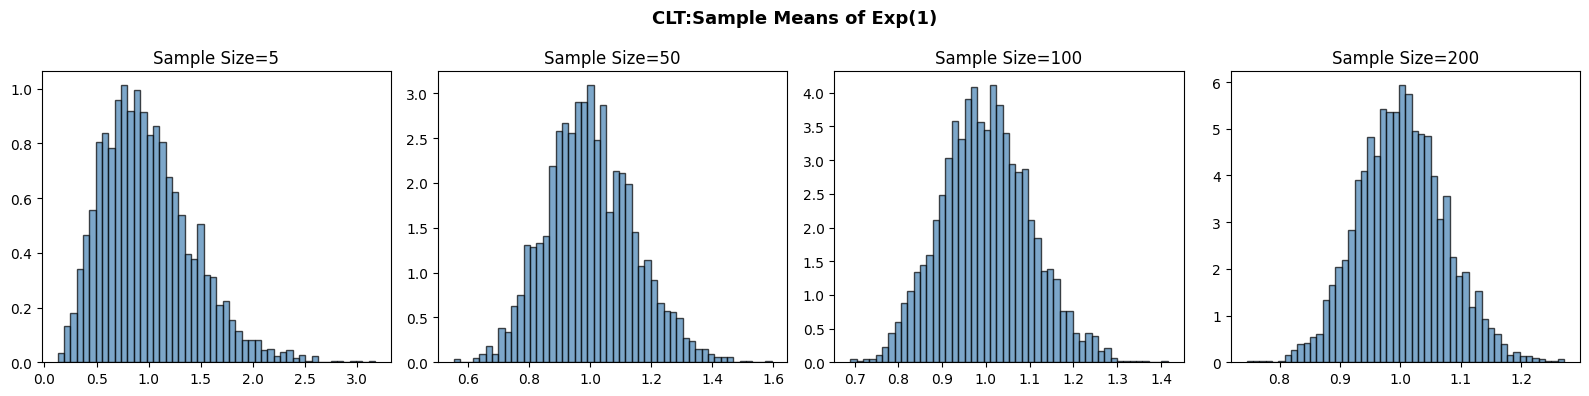

In [18]:
#--CENTRAL LIMIT THEOREM--
sample_size=[5,50,100,200]
fig,axes=plt.subplots(1,4,figsize=(16,4))

for i,n in enumerate(sample_size):
  means=[np.mean(np.random.exponential(1,n)) for _ in range(3000)]
  axes[i].hist(means,bins=50,density=True,color='steelBlue',edgecolor='black',alpha=0.7)
  axes[i].set_title(f'n={n}\n Mean={np.mean(means) :.3f}')
  axes[i].set_title(f'Sample Size={n}')

fig.suptitle('CLT:Sample Means of Exp(1)',fontsize=13,fontweight='bold')
plt.tight_layout()
plt.show()